In [2]:
# LOADING PACKAGES #
import math, random
import matplotlib.pyplot as plt
import numpy as np


In [10]:
# SIMULATION #

# Setting parameters #
MAXTIME = 1000 # run the simulation until this time
TIMESTEP = 0.001 # size of the timestep
SYSLENGTH = 50 # length of the system to simulate
SPACESTEP = 1 # size of the spatial step

PERTURB = 0.05 # sd of the Gaussian from which to sample the initial perturbation of mirkanarf
PDEparams = [0, -0.5, -1, -0.5, -1, -1, 1, 0, 0] # k-parameters of the PDE
D_mirkanarf = 7.5 # diffusion coefficient for miRKANARF
D_astasiarf = 75 # diffusion coefficient for AStasiARF

SEED = 2 # Seed for the random number generator
TIMECOUNT = math.ceil(MAXTIME / TIMESTEP) + 1 # number of timesteps to compute
SPACECOUNT = math.ceil(SYSLENGTH / SPACESTEP) + 1 # number of spatial coordinates to compute


# Defining the simulation #
def simulate():
    # create initial arrays
    hdzip3 = np.zeros((TIMECOUNT, SPACECOUNT))
    mirkanarf = np.copy(hdzip3)
    astasiarf = np.copy(hdzip3)
    
    # introduce random perturbations in mirkanarf
    random.seed(SEED)
    for i in range(SPACECOUNT):
        mirkanarf[0][i] = random.gauss(mu=0, sigma=PERTURB)
    
    # run the time evolution
    for t in range(1, TIMECOUNT):
        for x in range(SPACECOUNT):
            hdzip3[t][x] = hdzip3[t-1][x] + TIMESTEP * hdzip3_step(t-1, x, hdzip3, mirkanarf, astasiarf)
            mirkanarf[t][x] = mirkanarf[t-1][x] + TIMESTEP * mirkanarf_step(t-1, x, hdzip3, mirkanarf, astasiarf)
            astasiarf[t][x] = astasiarf[t-1][x] + TIMESTEP * astasiarf_step(t-1, x, hdzip3, mirkanarf, astasiarf)

    return hdzip3, mirkanarf, astasiarf      

def hdzip3_step(t, x, hdzip3, mirkanarf, astasiarf):
    '''Compute the change in HDZIPIII given the current state of the system'''
    return PDEparams[0] * hdzip3[t][x] + PDEparams[1] * mirkanarf[t][x] + PDEparams[2] * astasiarf[t][x]

def mirkanarf_step(t, x, hdzip3, mirkanarf, astasiarf):
    '''Compute the change in miRKANARF given the current state of the system'''
    return PDEparams[3] * hdzip3[t][x] + PDEparams[4] * mirkanarf[t][x] + PDEparams[5] * astasiarf[t][x] + D_mirkanarf * laplace(mirkanarf[t], x)

def astasiarf_step(t, x, hdzip3, mirkanarf, astasiarf):
    '''Compute the change in AStasiARF given the current state of the system'''
    return PDEparams[6] * hdzip3[t][x] + PDEparams[7] * mirkanarf[t][x] + PDEparams[8] * astasiarf[t][x] + D_astasiarf * laplace(astasiarf[t], x)

def laplace(array, x):
    '''Compute 1D Laplacian at position x with periodic boundaries. Function created with the help of MistralAI'''
    x_prev = (x - 1) % SPACECOUNT  # Wrap around for periodic BC
    x_next = (x + 1) % SPACECOUNT
    return (array[x_next] - 2 * array[x] + array[x_prev]) / (SPACESTEP ** 2)

# Running the simulation #
hdzip3, mirkanarf, astasiarf = simulate()

Text(0.5, 0.98, 'Reproduction of Fig. S8A from Scacchi et al.')

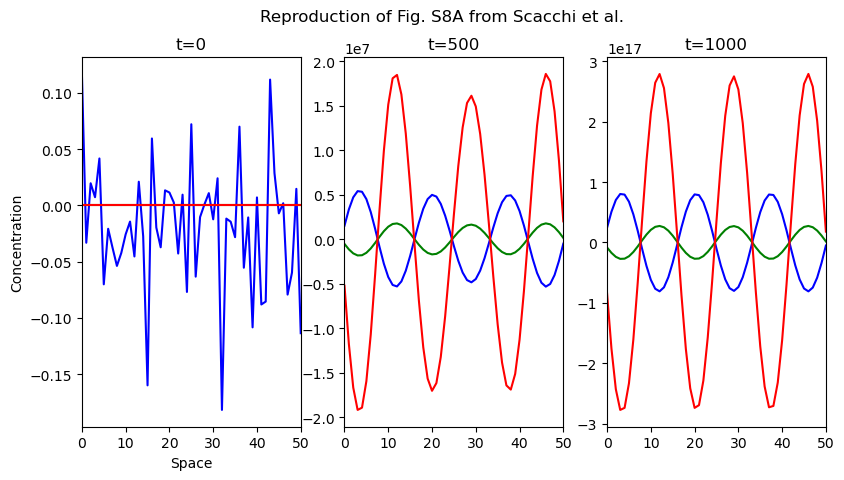

In [15]:
# VISUALIZATION #
TIMESTEPS_TO_PLOT = [0, 500, 1000]
space = np.arange(0, SYSLENGTH + SPACESTEP, SPACESTEP) # spatial dimension array

fig, ax = plt.subplots(1, len(TIMESTEPS_TO_PLOT))
fig.set_figwidth(6.4*len(TIMESTEPS_TO_PLOT)*0.5)
for i in range(len(TIMESTEPS_TO_PLOT)):
    ax[i].plot(space, mirkanarf[int(TIMESTEPS_TO_PLOT[i] / TIMESTEP)], color='blue')
    ax[i].plot(space, astasiarf[int(TIMESTEPS_TO_PLOT[i] / TIMESTEP)], color='green')
    ax[i].plot(space, hdzip3[int(TIMESTEPS_TO_PLOT[i] / TIMESTEP)], color='red')

    ax[i].set_xlim(0, SYSLENGTH)
    ax[i].set_title(f't={TIMESTEPS_TO_PLOT[i]}')

ax[0].set_xlabel("Space")
ax[0].set_ylabel("Concentration")
fig.suptitle("Reproduction of Fig. S8A from Scacchi et al.")